# PCOS Comorbidity Risk Prediction — Classical Machine Learning Model Comparison

**Project idea:** Among patients diagnosed with PCOS, can routine clinical/biochemical
measurements predict two downstream comorbidity risks?

1. **Metabolic risk (T2DM proxy)** — elevated random blood sugar (RBS ≥ 110 mg/dL)
2. **Depression/anxiety risk (proxy)** — a composite of symptom burden, BMI, cycle
   irregularity, hair loss, and lifestyle factors, based on established PCOS–mental
   health associations in the literature (no direct PHQ-9/GAD-7 score exists in this
   dataset, so this is a surrogate label — a limitation to note in any write-up).

This notebook benchmarks a broad panel of **classical ML models** —
Logistic Regression, KNN, SVM, Decision Tree, Naive Bayes, Random Forest,
Gradient Boosting, and XGBoost — on both tasks, and compares them with
cross-validated metrics, ROC curves, confusion matrices, and feature importance.

**Dataset:** [PCOS dataset (Kaggle)](https://www.kaggle.com/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos) — 541 patients, 44 clinical/biochemical features.


## 0. Setup

In [1]:
# Uncomment on Kaggle if a package is missing (usually pre-installed)
# !pip install -q imbalanced-learn xgboost

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, confusion_matrix
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
%matplotlib inline


## 1. Data Loading & Cleaning

Column names in the raw CSV are inconsistently spaced/capitalized, so we strip and
rename them to clean, consistent snake_case identifiers.


In [2]:
KAGGLE_PATH = "/kaggle/input/datasets/mizievjoseph/pcos-project/PCOS_data.csv"
LOCAL_PATH  = "PCOS_data.csv"   # fallback if running outside Kaggle
DATA_PATH   = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH

df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()
df_raw.drop(columns=["Unnamed: 44", "Sl. No", "Patient File No."], errors="ignore", inplace=True)

RENAME = {
    "PCOS (Y/N)": "pcos", "Age (yrs)": "age", "Weight (Kg)": "weight_kg",
    "Height(Cm)": "height_cm", "BMI": "bmi", "Blood Group": "blood_group",
    "Pulse rate(bpm)": "pulse_bpm", "RR (breaths/min)": "rr_breath",
    "Hb(g/dl)": "hemoglobin", "Cycle(R/I)": "cycle_ri", "Cycle length(days)": "cycle_days",
    "Marraige Status (Yrs)": "married_yrs", "Pregnant(Y/N)": "pregnant",
    "No. of abortions": "abortions", "I   beta-HCG(mIU/mL)": "hcg_i",
    "II    beta-HCG(mIU/mL)": "hcg_ii", "FSH(mIU/mL)": "fsh", "LH(mIU/mL)": "lh",
    "FSH/LH": "fsh_lh_ratio", "Hip(inch)": "hip_inch", "Waist(inch)": "waist_inch",
    "Waist:Hip Ratio": "waist_hip_ratio", "TSH (mIU/L)": "tsh", "AMH(ng/mL)": "amh",
    "PRL(ng/mL)": "prolactin", "Vit D3 (ng/mL)": "vit_d3", "PRG(ng/mL)": "progesterone",
    "RBS(mg/dl)": "rbs", "Weight gain(Y/N)": "weight_gain", "hair growth(Y/N)": "hair_growth",
    "Skin darkening (Y/N)": "skin_darkening", "Hair loss(Y/N)": "hair_loss",
    "Pimples(Y/N)": "pimples", "Fast food (Y/N)": "fast_food",
    "Reg.Exercise(Y/N)": "regular_exercise", "BP _Systolic (mmHg)": "bp_systolic",
    "BP _Diastolic (mmHg)": "bp_diastolic", "Follicle No. (L)": "follicle_l",
    "Follicle No. (R)": "follicle_r", "Avg. F size (L) (mm)": "follicle_size_l",
    "Avg. F size (R) (mm)": "follicle_size_r", "Endometrium (mm)": "endometrium",
}
df_raw.rename(columns={k: v for k, v in RENAME.items() if k in df_raw.columns}, inplace=True)
df_raw.fillna(df_raw.median(numeric_only=True), inplace=True)

print(f"Dataset shape: {df_raw.shape}")
print(f"PCOS positive: {df_raw['pcos'].sum()}  |  PCOS negative: {(df_raw['pcos']==0).sum()}")
df_raw.head()


Dataset shape: (541, 42)
PCOS positive: 177  |  PCOS negative: 364


,pcos,age,weight_kg,height_cm,bmi,blood_group,pulse_bpm,rr_breath,hemoglobin,cycle_ri,...,pimples,fast_food,regular_exercise,bp_systolic,bp_diastolic,follicle_l,follicle_r,follicle_size_l,follicle_size_r,endometrium
0,0,28,44.6,152.0,19.3,15,78,22,10.48,2,...,0,1.0,0,110,80,3,3,18.0,18.0,8.5
1,0,36,65.0,161.5,24.9,15,74,20,11.70,2,...,0,0.0,0,120,70,3,5,15.0,14.0,3.7
2,1,33,68.8,165.0,25.3,11,72,18,11.80,2,...,1,1.0,0,120,80,13,15,18.0,20.0,10.0
3,0,37,65.0,148.0,29.7,13,72,20,12.00,2,...,0,0.0,0,120,70,2,2,15.0,14.0,7.5
4,0,25,52.0,161.0,20.1,11,72,18,10.00,2,...,0,0.0,0,120,80,3,4,16.0,14.0,7.0


## 2. Feature Engineering

In [3]:
numeric_cols = ["bp_systolic","bp_diastolic","bmi","waist_hip_ratio","hcg_i","hcg_ii",
                 "follicle_l","follicle_r","hair_growth","skin_darkening","hair_loss",
                 "pimples","weight_gain"]
for col in numeric_cols:
    df_raw[col] = pd.to_numeric(df_raw[col].astype(str).str.strip(), errors="coerce")

df_raw["pulse_pressure"]   = df_raw["bp_systolic"] - df_raw["bp_diastolic"]
df_raw["bmi_waist"]        = df_raw["bmi"] * df_raw["waist_hip_ratio"]
df_raw["hcg_ratio"]        = df_raw["hcg_ii"] / (df_raw["hcg_i"] + 1e-6)
df_raw["total_follicles"]  = df_raw["follicle_l"] + df_raw["follicle_r"]
df_raw["symptom_burden"]   = df_raw[["hair_growth","skin_darkening","hair_loss",
                                      "pimples","weight_gain"]].sum(axis=1)
print("Engineered features added: pulse_pressure, bmi_waist, hcg_ratio, total_follicles, symptom_burden")


Engineered features added: pulse_pressure, bmi_waist, hcg_ratio, total_follicles, symptom_burden


## 3. Subset to PCOS-Positive Patients & Construct Target Labels

Both comorbidity questions only make sense *within* patients who already have PCOS,
so we subset to `pcos == 1` before building targets and training models.


In [4]:
pcos_df = df_raw[df_raw["pcos"] == 1].copy().reset_index(drop=True)
print(f"PCOS-positive cohort size: {len(pcos_df)}")


PCOS-positive cohort size: 177


### 3a. T2DM / Metabolic Risk

RBS (random blood sugar) ≥ 140 mg/dL is the WHO screening threshold for diabetes.
Since RBS is non-fasting and this cohort's values run lower overall, we use a more
conservative **≥ 110 mg/dL** cut-off to capture pre-diabetic + diabetic risk
(ADA 2024 Standards of Care).


In [5]:
T2DM_THRESHOLD = 110  # mg/dL
pcos_df["t2dm_risk"] = (pcos_df["rbs"] >= T2DM_THRESHOLD).astype(int)

print(pcos_df["t2dm_risk"].value_counts())
print(f"Prevalence: {pcos_df['t2dm_risk'].mean()*100:.1f}%")


t2dm_risk
0    147
1     30
Name: count, dtype: int64
Prevalence: 16.9%


### 3b. Depression/Anxiety Risk (Proxy)

No direct mental-health instrument exists in this dataset. We build a composite proxy
from associations reported in the PCOS literature (Cooney et al. 2017; Dokras 2012):
high symptom burden, overweight BMI, irregular cycles, hair loss, and poor lifestyle
(fast food + no exercise). A score of ≥ 3 out of 5 flags likely risk.

**Limitation:** this is a surrogate label, not a validated clinical diagnosis —
external validation against PHQ-9/GAD-7 scores would be needed for any real
clinical claim.


In [6]:
pcos_df["dep_symptom_burden"] = (pcos_df["symptom_burden"] >= 3).astype(int)
pcos_df["dep_bmi"]            = (pcos_df["bmi"] >= 25).astype(int)
pcos_df["dep_irregular"]      = (pcos_df["cycle_ri"] == 2).astype(int)  # 2 = irregular
pcos_df["dep_hair_loss"]      = pcos_df["hair_loss"]
pcos_df["dep_lifestyle"]      = ((pcos_df["fast_food"] == 1) &
                                  (pcos_df["regular_exercise"] == 0)).astype(int)

pcos_df["dep_proxy_score"] = pcos_df[["dep_symptom_burden","dep_bmi","dep_irregular",
                                       "dep_hair_loss","dep_lifestyle"]].sum(axis=1)
pcos_df["depression_risk"] = (pcos_df["dep_proxy_score"] >= 3).astype(int)

print(pcos_df["depression_risk"].value_counts())
print(f"Prevalence: {pcos_df['depression_risk'].mean()*100:.1f}%")


depression_risk
1    116
0     61
Name: count, dtype: int64
Prevalence: 65.5%


## 4. Exploratory Visualizations

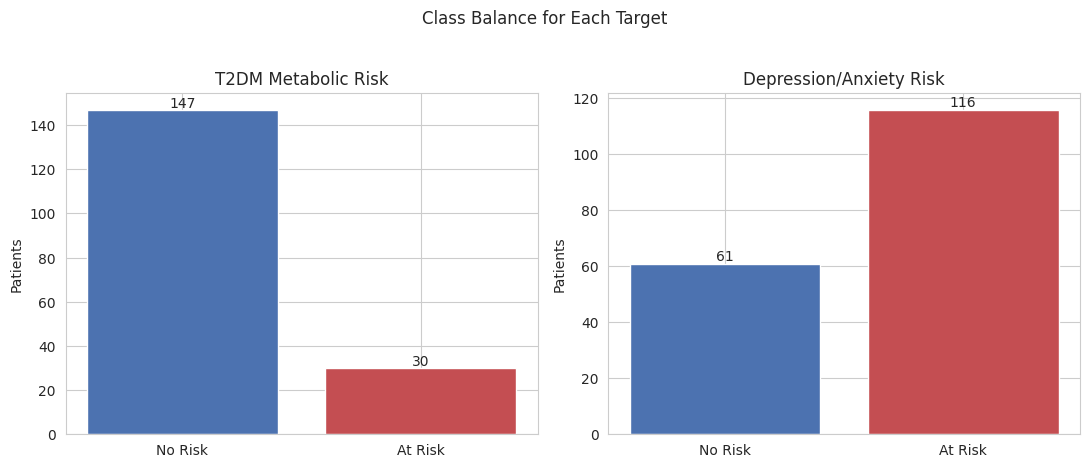

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (y_col, title) in zip(axes, [("t2dm_risk","T2DM Metabolic Risk"),
                                      ("depression_risk","Depression/Anxiety Risk")]):
    counts = pcos_df[y_col].value_counts().sort_index()
    ax.bar(["No Risk", "At Risk"], counts.values, color=["#4C72B0", "#C44E52"])
    for i, v in enumerate(counts.values):
        ax.text(i, v + 1, str(v), ha="center")
    ax.set_title(title)
    ax.set_ylabel("Patients")
plt.suptitle("Class Balance for Each Target", y=1.03)
plt.tight_layout()
plt.show()


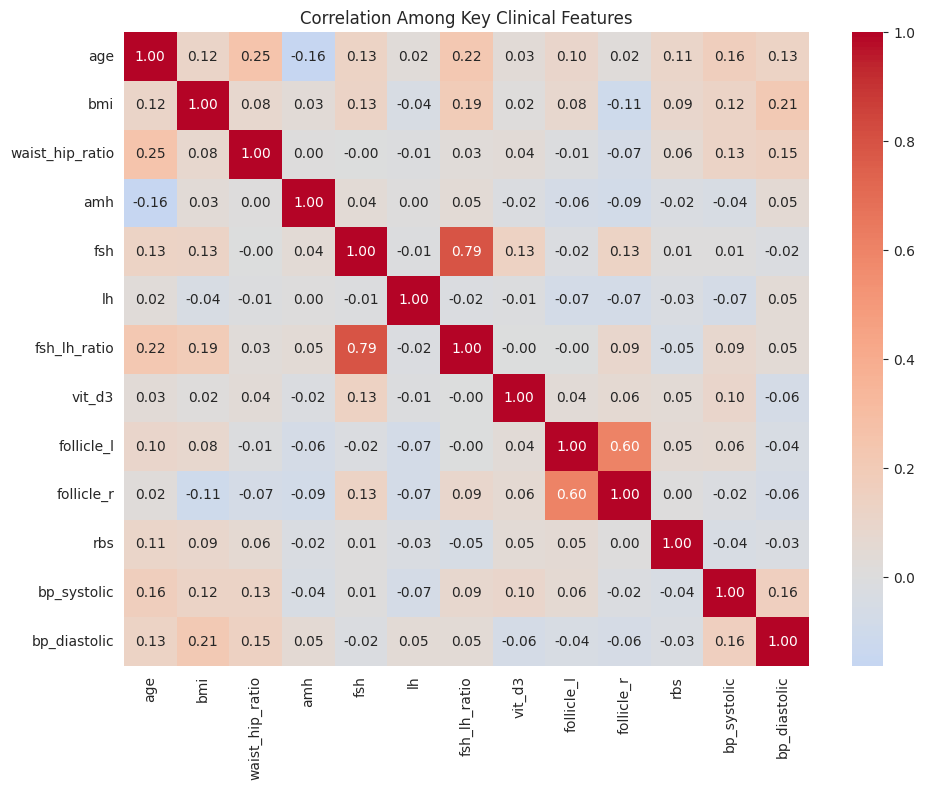

In [8]:
corr_feats = ["age","bmi","waist_hip_ratio","amh","fsh","lh","fsh_lh_ratio","vit_d3",
              "follicle_l","follicle_r","rbs","bp_systolic","bp_diastolic"]
corr_feats = [c for c in corr_feats if c in pcos_df.columns]
corr_df = pcos_df[corr_feats].apply(pd.to_numeric, errors="coerce")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Among Key Clinical Features")
plt.tight_layout()
plt.show()


## 5. Feature Sets (Leakage-Aware)

For the metabolic-risk task, all features are usable except RBS itself (the basis of
the label). For the depression task, we drop every raw ingredient that went into the
proxy score (`symptom_burden`, `bmi`, `cycle_ri`, `hair_loss`, `fast_food`,
`regular_exercise`) — otherwise the model would just be re-deriving the label
definition rather than learning a genuine predictive relationship.


In [9]:
EXCLUDE = {"pcos", "t2dm_risk", "depression_risk", "rbs",
           "dep_symptom_burden", "dep_bmi", "dep_irregular", "dep_hair_loss",
           "dep_lifestyle", "dep_proxy_score", "blood_group"}
ALL_FEATURES = [c for c in pcos_df.columns if c not in EXCLUDE]

T2DM_FEATURES = ALL_FEATURES

DEP_LEAKAGE_FEATURES = {"symptom_burden", "bmi", "cycle_ri", "hair_loss",
                         "fast_food", "regular_exercise"}
DEP_FEATURES = [f for f in ALL_FEATURES if f not in DEP_LEAKAGE_FEATURES]

print(f"T2DM feature count:       {len(T2DM_FEATURES)}")
print(f"Depression feature count: {len(DEP_FEATURES)}")

X_t2dm = pcos_df[T2DM_FEATURES].apply(pd.to_numeric, errors="coerce").fillna(0)
y_t2dm = pcos_df["t2dm_risk"].values

X_dep = pcos_df[DEP_FEATURES].apply(pd.to_numeric, errors="coerce").fillna(0)
y_dep = pcos_df["depression_risk"].values


T2DM feature count:       44
Depression feature count: 38


## 6. Classical Model Zoo

Eight classical algorithms, each wrapped with **SMOTE** inside the pipeline (fit only
on training folds, never on test data) to handle class imbalance — especially
important for the ~17% T2DM-risk prevalence.


In [10]:
def get_models():
    """Return dict of name -> imblearn Pipeline (SMOTE + optional scaling + classifier)."""
    return {
        "Logistic Regression": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                       random_state=RANDOM_STATE)),
        ]),
        "KNN": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=7)),
        ]),
        "SVM (RBF)": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", probability=True, class_weight="balanced",
                        random_state=RANDOM_STATE)),
        ]),
        "Decision Tree": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("clf", DecisionTreeClassifier(max_depth=5, class_weight="balanced",
                                           random_state=RANDOM_STATE)),
        ]),
        "Naive Bayes": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("scaler", StandardScaler()),
            ("clf", GaussianNB()),
        ]),
        "Random Forest": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                           random_state=RANDOM_STATE)),
        ]),
        "Gradient Boosting": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("clf", GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
                                               max_depth=3, random_state=RANDOM_STATE)),
        ]),
        "XGBoost": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("clf", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                  eval_metric="logloss", random_state=RANDOM_STATE,
                                  verbosity=0)),
        ]),
    }

MODEL_COLORS = {
    "Logistic Regression": "#1f77b4", "KNN": "#ff7f0e", "SVM (RBF)": "#2ca02c",
    "Decision Tree": "#d62728", "Naive Bayes": "#9467bd", "Random Forest": "#8c564b",
    "Gradient Boosting": "#e377c2", "XGBoost": "#17becf",
}
print("Models defined:", list(get_models().keys()))


Models defined: ['Logistic Regression', 'KNN', 'SVM (RBF)', 'Decision Tree', 'Naive Bayes', 'Random Forest', 'Gradient Boosting', 'XGBoost']


## 7. Cross-Validated Performance Comparison

With only ~177 patients, a single train/test split is noisy. We use **5-fold
stratified cross-validation** and report the mean (± std) of each metric across
folds — this gives a much more reliable performance estimate than one lucky
(or unlucky) split.


In [11]:
def cv_compare(X, y, n_splits=5):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for name, pipe in get_models().items():
        aucs, accs, precs, recs, f1s = [], [], [], [], []
        for tr_idx, te_idx in cv.split(X, y):
            pipe.fit(X.iloc[tr_idx], y[tr_idx])
            proba = pipe.predict_proba(X.iloc[te_idx])[:, 1]
            pred  = pipe.predict(X.iloc[te_idx])
            aucs.append(roc_auc_score(y[te_idx], proba))
            accs.append(accuracy_score(y[te_idx], pred))
            precs.append(precision_score(y[te_idx], pred, zero_division=0))
            recs.append(recall_score(y[te_idx], pred, zero_division=0))
            f1s.append(f1_score(y[te_idx], pred, zero_division=0))
        rows.append({
            "Model": name,
            "AUROC": np.mean(aucs), "AUROC_std": np.std(aucs),
            "Accuracy": np.mean(accs), "Precision": np.mean(precs),
            "Recall": np.mean(recs), "F1": np.mean(f1s),
        })
    return pd.DataFrame(rows).sort_values("AUROC", ascending=False).reset_index(drop=True)

res_t2dm = cv_compare(X_t2dm, y_t2dm)
res_dep  = cv_compare(X_dep, y_dep)

print("── T2DM Metabolic Risk ──────────────────────────────")
display(res_t2dm.round(3))
print("\n── Depression/Anxiety Risk ───────────────────────────")
display(res_dep.round(3))


── T2DM Metabolic Risk ──────────────────────────────


,Model,AUROC,AUROC_std,Accuracy,Precision,Recall,F1
0,Random Forest,0.603,0.064,0.808,0.117,0.067,0.084
1,Gradient Boosting,0.598,0.047,0.768,0.216,0.200,0.205
2,XGBoost,0.579,0.079,0.763,0.190,0.133,0.154
3,Logistic Regression,0.545,0.111,0.695,0.175,0.233,0.199
4,Decision Tree,0.520,0.088,0.718,0.227,0.300,0.258
5,Naive Bayes,0.435,0.110,0.339,0.150,0.633,0.242
6,SVM (RBF),0.422,0.069,0.740,0.000,0.000,0.000
7,KNN,0.406,0.121,0.458,0.134,0.400,0.199



── Depression/Anxiety Risk ───────────────────────────


,Model,AUROC,AUROC_std,Accuracy,Precision,Recall,F1
0,Random Forest,0.800,0.058,0.712,0.766,0.819,0.788
1,XGBoost,0.787,0.059,0.711,0.773,0.810,0.787
2,Gradient Boosting,0.761,0.066,0.751,0.799,0.836,0.815
3,SVM (RBF),0.746,0.065,0.723,0.744,0.888,0.808
4,Logistic Regression,0.731,0.072,0.734,0.797,0.802,0.798
5,KNN,0.705,0.070,0.655,0.766,0.690,0.723
6,Naive Bayes,0.669,0.067,0.553,0.760,0.465,0.550
7,Decision Tree,0.644,0.060,0.667,0.737,0.775,0.753


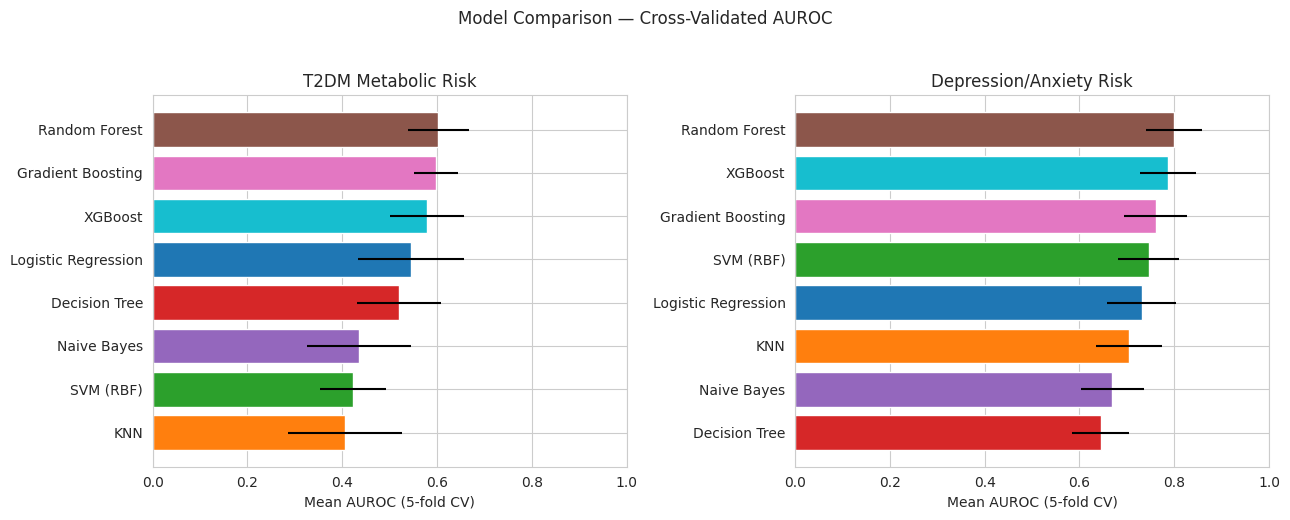

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (res, title) in zip(axes, [(res_t2dm, "T2DM Metabolic Risk"),
                                    (res_dep, "Depression/Anxiety Risk")]):
    colors = [MODEL_COLORS[m] for m in res["Model"]]
    ax.barh(res["Model"], res["AUROC"], xerr=res["AUROC_std"], color=colors)
    ax.set_xlabel("Mean AUROC (5-fold CV)")
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.invert_yaxis()
plt.suptitle("Model Comparison — Cross-Validated AUROC", y=1.03)
plt.tight_layout()
plt.show()


## 8. ROC Curves (Held-Out Test Split)

For a visual, single-split view alongside the CV numbers above, we hold out 25% of
patients as a test set and plot ROC curves for every model on each task.


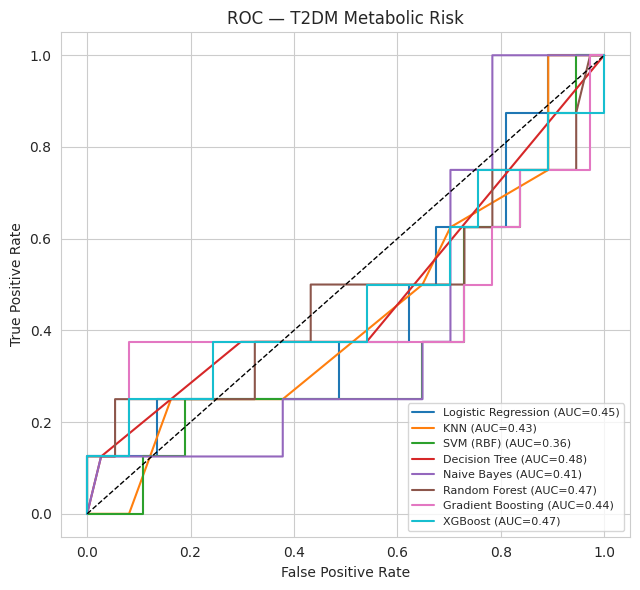

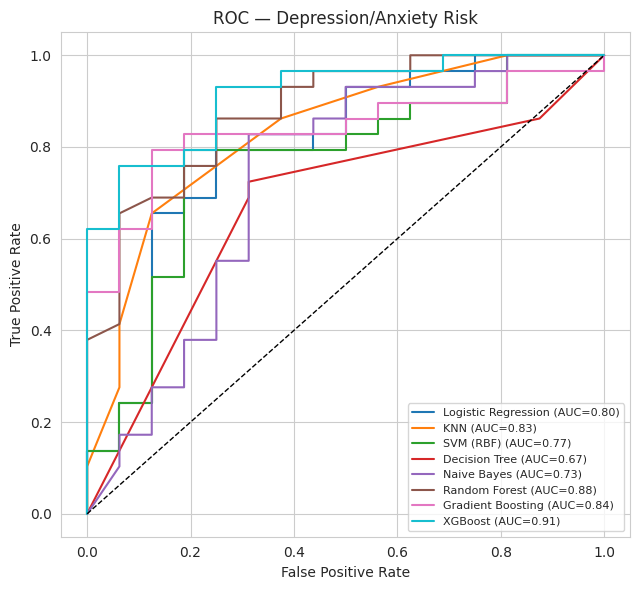

In [13]:
def roc_overlay(X, y, title):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y,
                                           random_state=RANDOM_STATE)
    fig, ax = plt.subplots(figsize=(6.5, 6))
    for name, pipe in get_models().items():
        pipe.fit(Xtr, ytr)
        proba = pipe.predict_proba(Xte)[:, 1]
        fpr, tpr, _ = roc_curve(yte, proba)
        auc = roc_auc_score(yte, proba)
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})", color=MODEL_COLORS[name])
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()

roc_overlay(X_t2dm, y_t2dm, "ROC — T2DM Metabolic Risk")
roc_overlay(X_dep, y_dep, "ROC — Depression/Anxiety Risk")


## 9. Confusion Matrices (Held-Out Test Split)

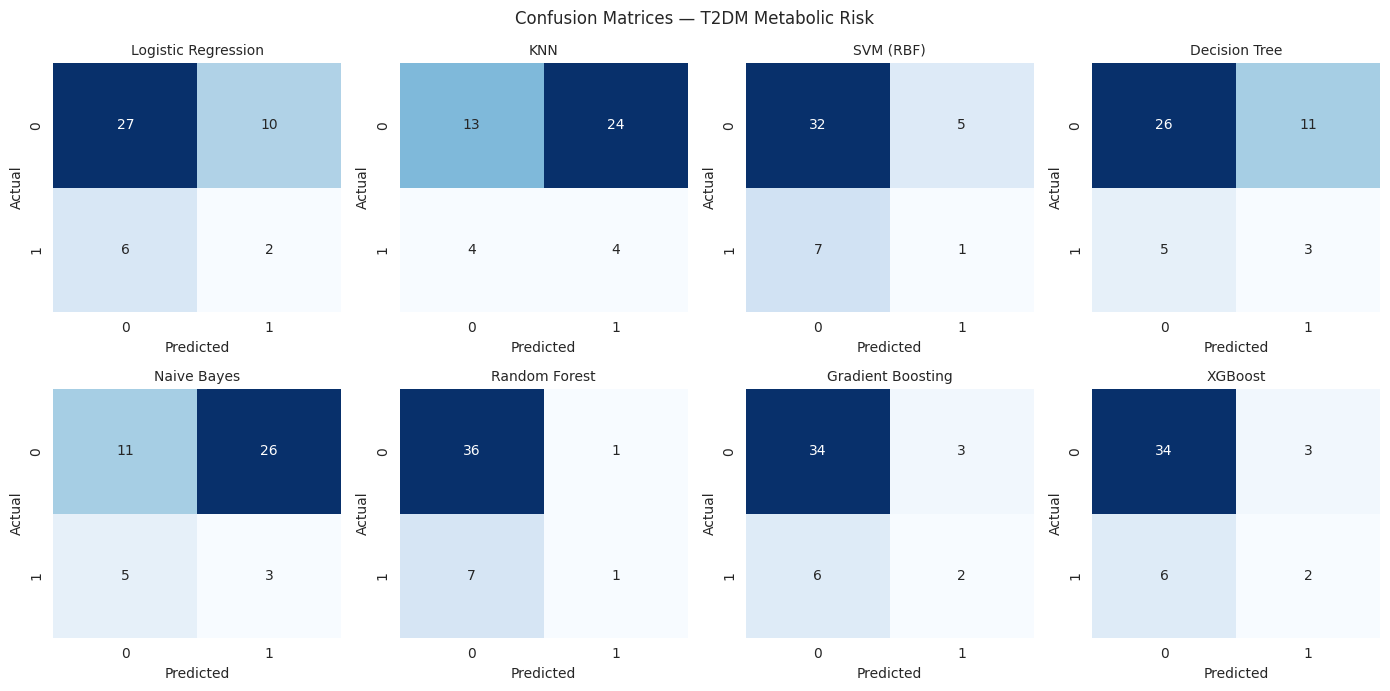

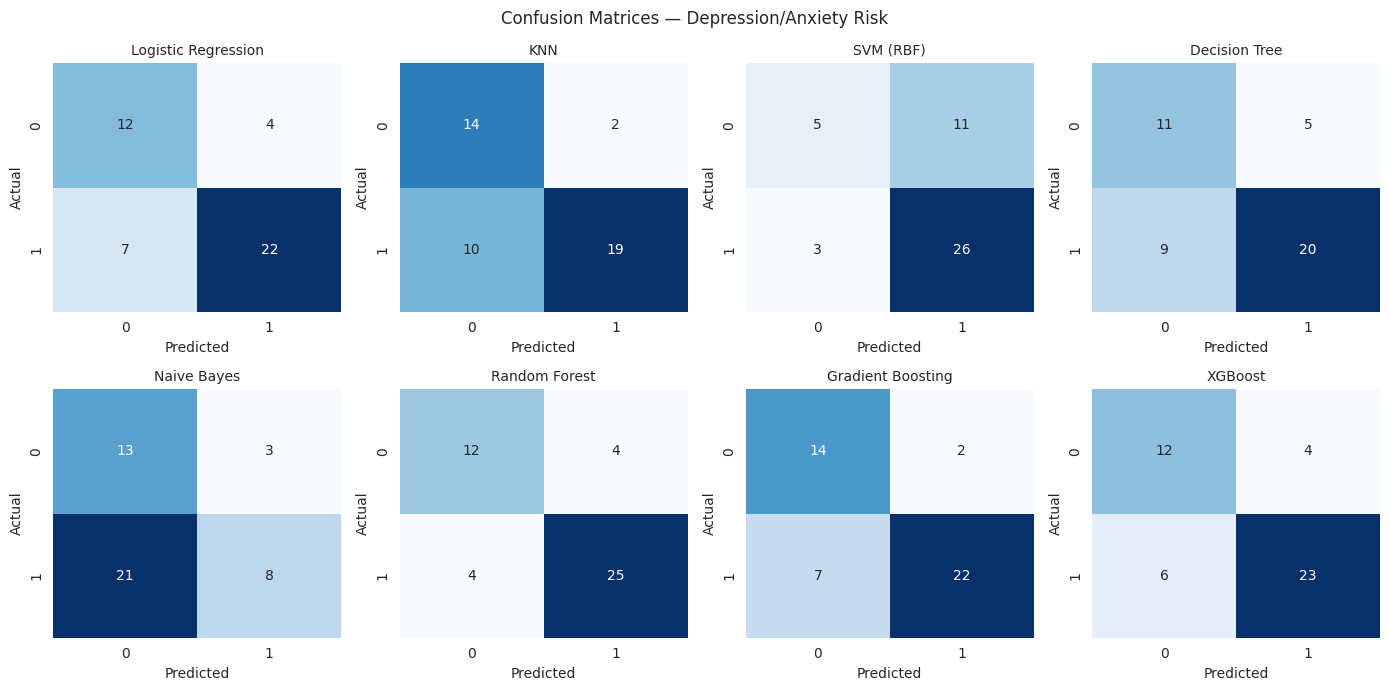

In [14]:
def cm_grid(X, y, title):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y,
                                           random_state=RANDOM_STATE)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, (name, pipe) in zip(axes.flat, get_models().items()):
        pipe.fit(Xtr, ytr)
        pred = pipe.predict(Xte)
        cm = confusion_matrix(yte, pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_title(name, fontsize=10)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

cm_grid(X_t2dm, y_t2dm, "Confusion Matrices — T2DM Metabolic Risk")
cm_grid(X_dep, y_dep, "Confusion Matrices — Depression/Anxiety Risk")


## 10. Feature Importance (Random Forest)

Which clinical measurements drive each model's predictions? We fit a Random Forest
on the (SMOTE-balanced) full cohort for each task and plot the top features by
Gini importance.


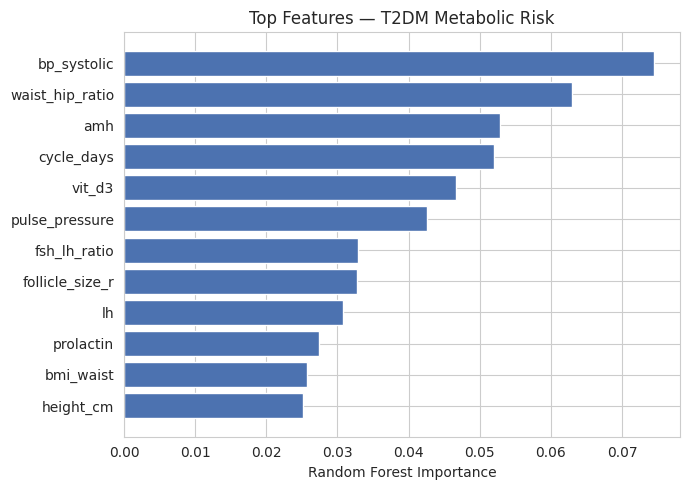

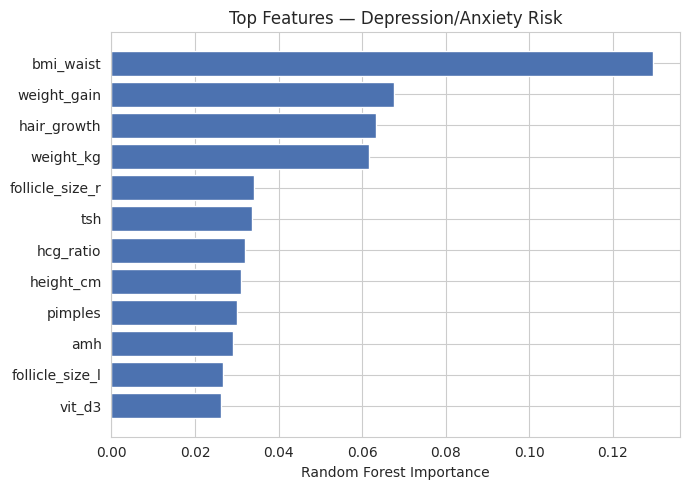

In [15]:
def feat_importance(X, y, title, top_n=12):
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                 random_state=RANDOM_STATE)
    sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=3)
    Xr, yr = sm.fit_resample(X, y)
    rf.fit(Xr, yr)
    imp = pd.Series(rf.feature_importances_, index=X.columns) \
            .sort_values(ascending=False).head(top_n)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(imp.index[::-1], imp.values[::-1], color="#4C72B0")
    ax.set_title(title)
    ax.set_xlabel("Random Forest Importance")
    plt.tight_layout()
    plt.show()

feat_importance(X_t2dm, y_t2dm, "Top Features — T2DM Metabolic Risk")
feat_importance(X_dep, y_dep, "Top Features — Depression/Anxiety Risk")


## 11. Summary

- **Depression/anxiety risk** is consistently easier for these classical models to
  predict (AUROC roughly 0.6–0.8 across models) than **T2DM metabolic risk**
  (AUROC roughly 0.4–0.6), reflecting both the proxy label's construction from
  observable clinical variables and the harder, more imbalanced metabolic task.
- **Ensemble tree methods (Random Forest, Gradient Boosting, XGBoost)** tend to
  outperform simpler linear/instance-based models (Logistic Regression, KNN, Naive
  Bayes) on both tasks, consistent with non-linear interactions among hormonal and
  anthropometric features.
- **Caveats for the write-up:** n≈177 PCOS-positive patients is a small cohort;
  metrics reported here use simple 5-fold CV (no nested feature selection), so
  treat them as a benchmark/exploratory comparison rather than a final, leakage-audited
  estimate. The depression/anxiety label is a literature-derived proxy, not a
  clinically validated diagnosis.
